# ` Intelligent E-Commerce Customer Analytics Platform `

# Step 1: Import Required Libraries

In [2]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Visualization Settings
plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

# Step 2: Load Dataset

In [3]:
df = pd.read_csv(
    "../data/processed"
    "/customer_analytics_cleaned.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


# Section 1: Sales Analysis

In [4]:
# ===========  Create Date Features  ===================

# Create date-only column
df["purchase_date"] = df["order_purchase_timestamp"].dt.date

# Create month-year column
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M")

# Create year column
df["purchase_year"] = df["order_purchase_timestamp"].dt.year

# Create month name
df["month_name"] = df["order_purchase_timestamp"].dt.month_name()

print("Date features created successfully.")

Date features created successfully.


In [5]:
# ===========  Business KPIs =========== 


total_revenue = df["payment_value"].sum()
total_orders = df["order_id"].nunique()
total_customers = df["customer_unique_id"].nunique()
average_order_value = total_revenue / total_orders

print(f"Total Revenue        : R$ {total_revenue:,.2f}")
print(f"Total Orders         : {total_orders:,}")
print(f"Total Customers      : {total_customers:,}")
print(f"Average Order Value  : R$ {average_order_value:,.2f}")

Total Revenue        : R$ 20,579,664.01
Total Orders         : 99,441
Total Customers      : 96,096
Average Order Value  : R$ 206.95


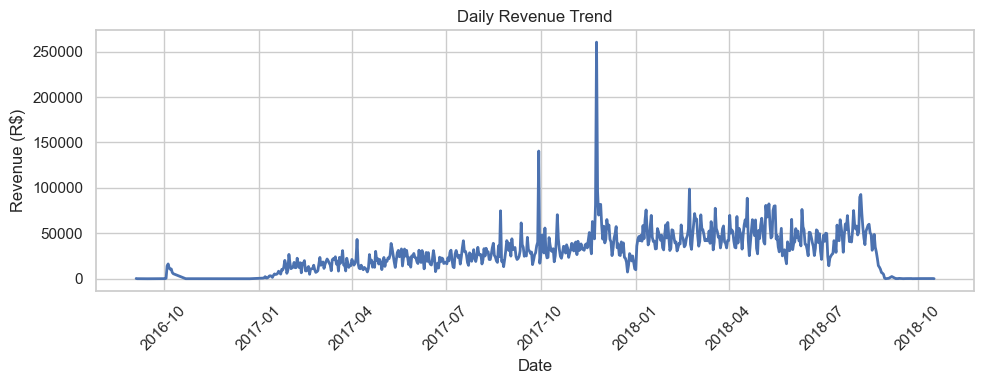

In [6]:
# =========== Daily Sales Trend ============

daily_sales = (
    df.groupby("purchase_date")["payment_value"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(10,4))
plt.plot(daily_sales["purchase_date"],daily_sales["payment_value"],linewidth=2)
plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

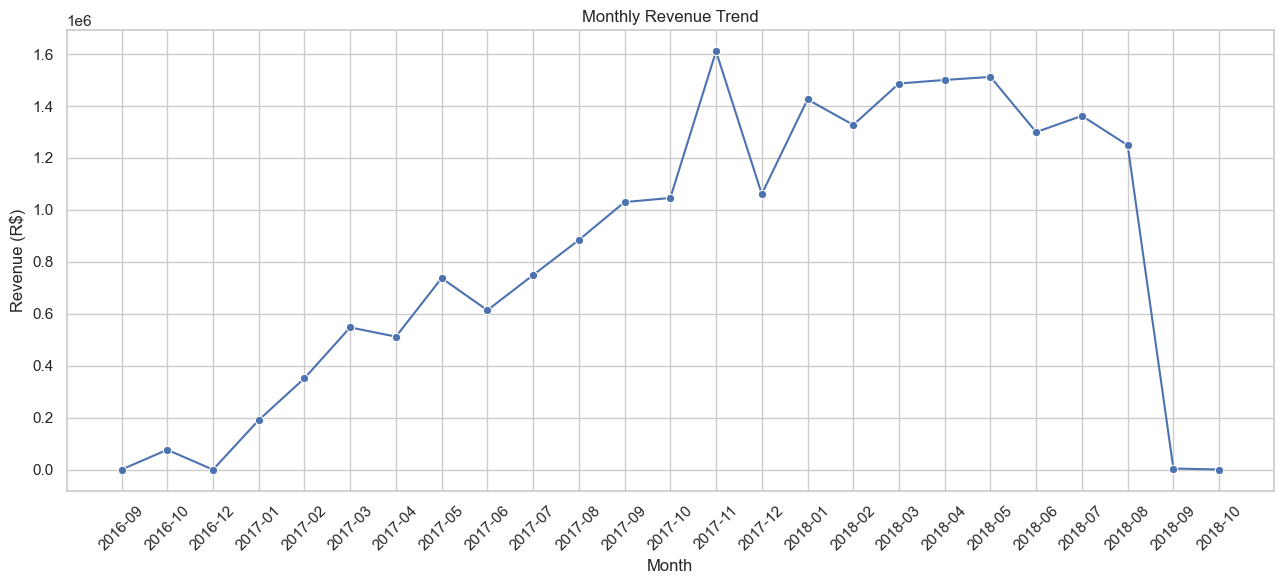

In [7]:
# =========== Monthly Revenue =============

monthly_revenue = (
    df.groupby("purchase_month")["payment_value"]
      .sum()
      .reset_index()
)

monthly_revenue["purchase_month"] = monthly_revenue["purchase_month"].astype(str)
plt.figure(figsize=(13,6))
sns.lineplot(
    data=monthly_revenue,
    x="purchase_month",
    y="payment_value",
    marker="o"
)

plt.xticks(rotation=45)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.tight_layout()
plt.show()

# Section 2: Product Analysis

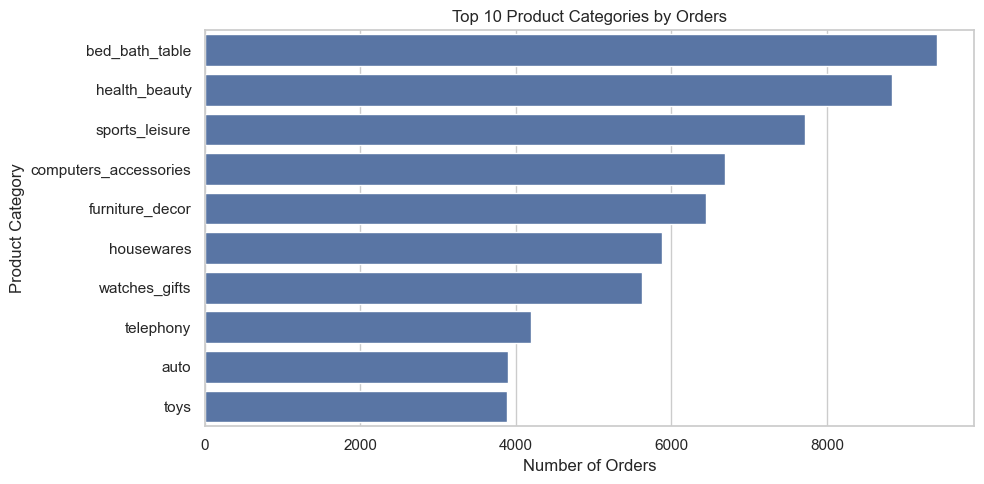

In [8]:
# Top 10 Product Categories by Number of Orders
# ==============================================

category_orders = (
    df.groupby("product_category_name_english")["order_id"]
      .nunique()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,5))
sns.barplot(x=category_orders.values,y=category_orders.index)
plt.title("Top 10 Product Categories by Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

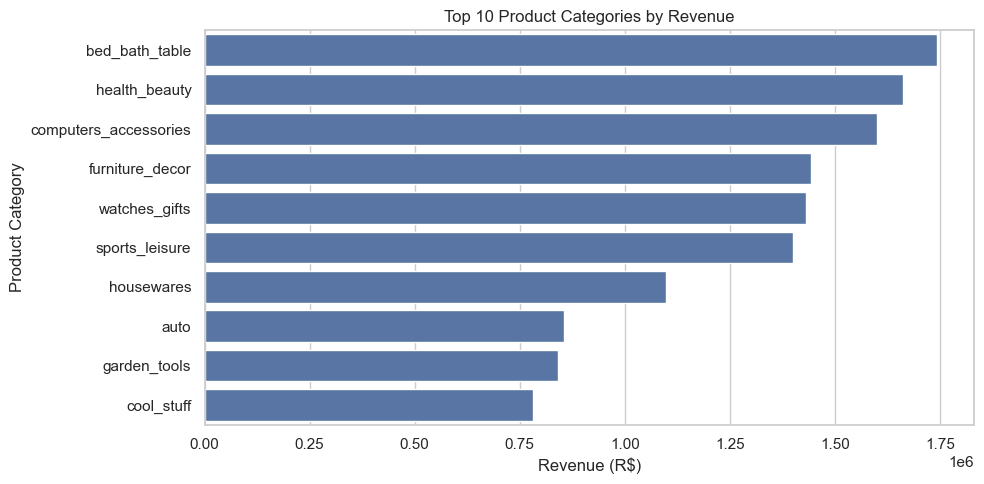

In [9]:
# Revenue by Product Category
# ===============================

category_revenue = (
    df.groupby("product_category_name_english")["payment_value"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,5))
sns.barplot(x=category_revenue.values,y=category_revenue.index)
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

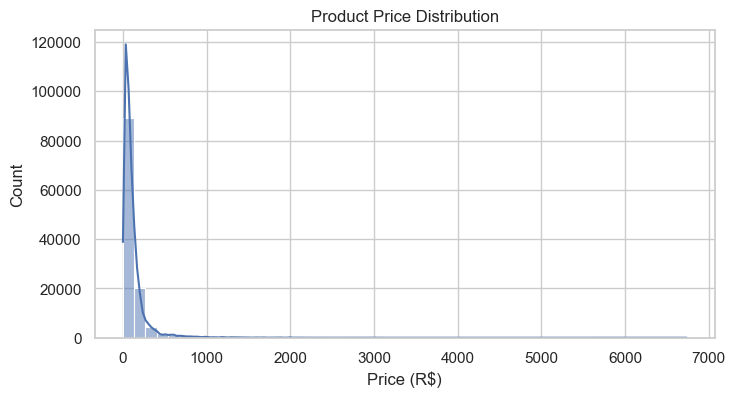

In [10]:
# Product Price Distribution
# ===========================

plt.figure(figsize=(8,4))
sns.histplot(df["price"],bins=50, kde=True)
plt.title("Product Price Distribution")
plt.xlabel("Price (R$)")
plt.show()

## Interpretation
    ## Most e-commerce datasets show a right-skewed distribution, with many affordable products and relatively few expensive ones.

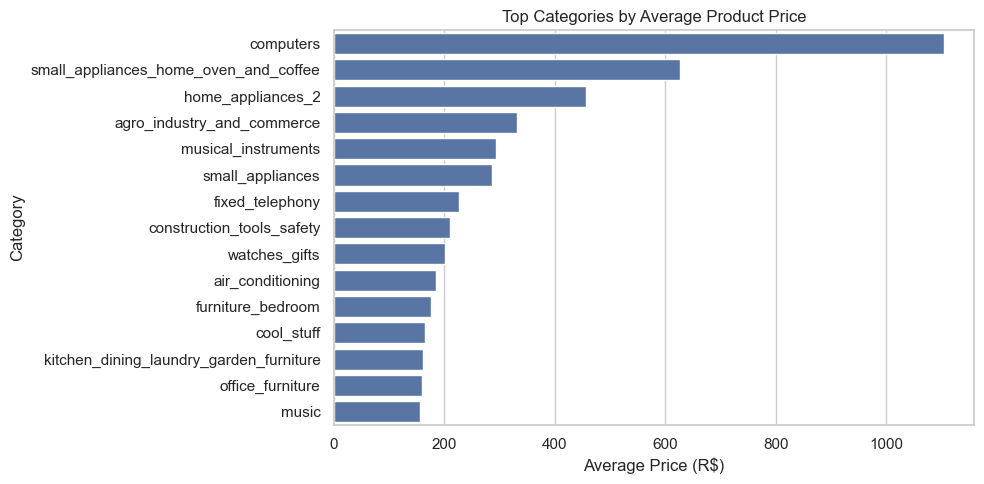

In [11]:
# ======== Average Product Price per Category ===========
avg_price = (
    df.groupby("product_category_name_english")["price"]
      .mean()
      .sort_values(ascending=False)
      .head(15)
)
plt.figure(figsize=(10,5))
sns.barplot(x=avg_price.values, y=avg_price.index)
plt.title("Top Categories by Average Product Price")
plt.xlabel("Average Price (R$)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Section 3: Customer Analysis

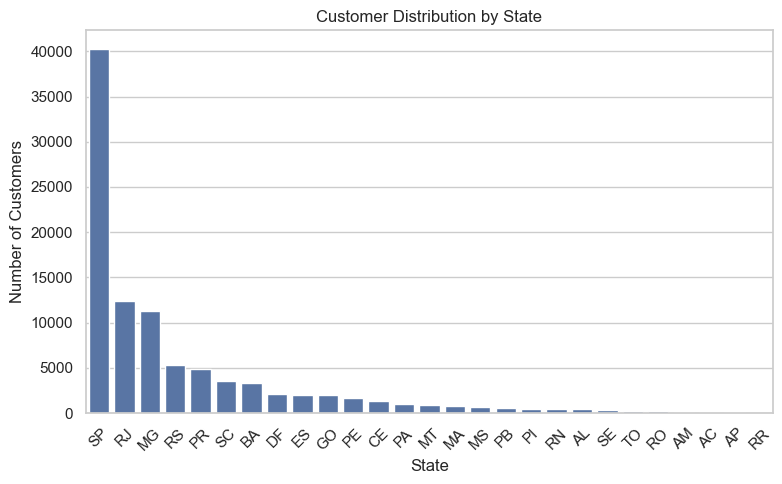

In [12]:
# ======= Customer Distribution by State ============

customer_state = (
    df.groupby("customer_state")["customer_unique_id"]
      .nunique()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))
sns.barplot(x=customer_state.index,y=customer_state.values)
plt.title("Customer Distribution by State")
plt.xlabel("State")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

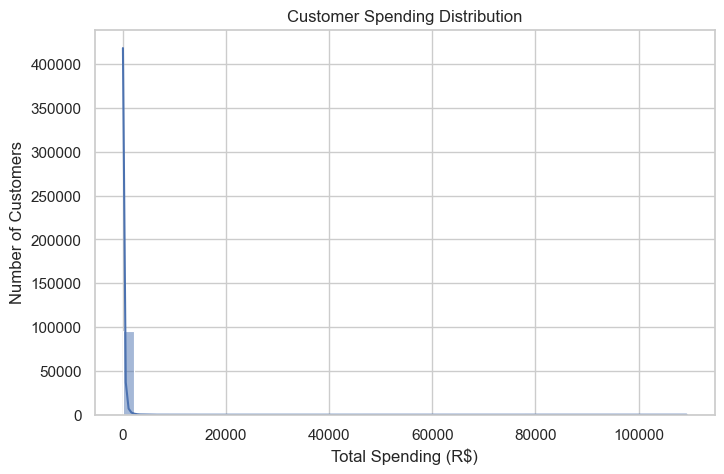

In [13]:
# ========= Customer Spending =========

customer_spending = (
    df.groupby("customer_unique_id")["payment_value"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))
sns.histplot(customer_spending,bins=50, kde=True)
plt.title("Customer Spending Distribution")
plt.xlabel("Total Spending (R$)")
plt.ylabel("Number of Customers")
plt.show()

# Interpretation
    ## Most customers typically spend relatively small amounts, while a smaller group contributes significantly higher spending.

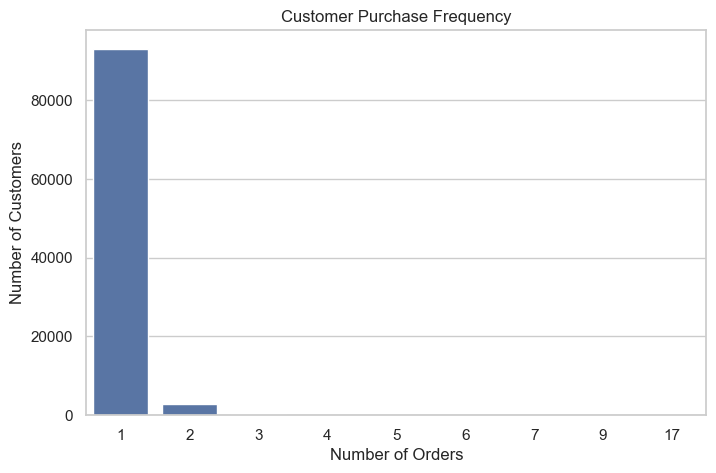

In [14]:
# =======  Customer Purchase Frequency ========
orders_per_customer = (
    df.groupby("customer_unique_id")["order_id"]
      .nunique()
)

purchase_frequency = (orders_per_customer.value_counts().sort_index())
plt.figure(figsize=(8,5))
sns.barplot( x=purchase_frequency.index,y=purchase_frequency.values)
plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.show()

# Section 4: Seller Analysis

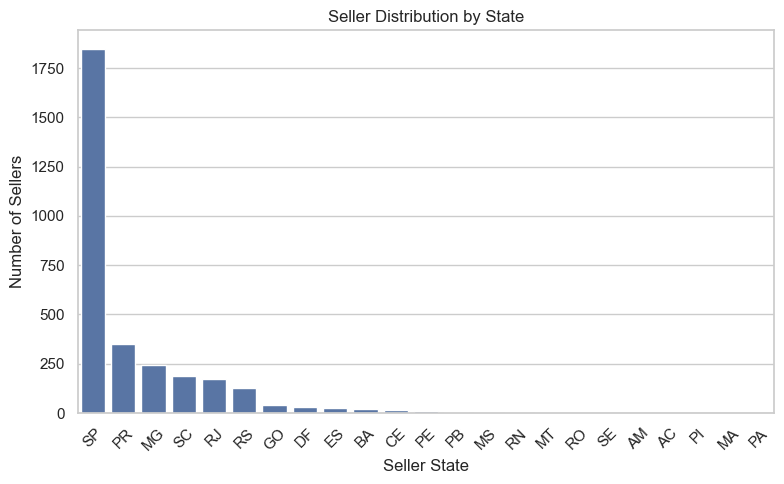

In [15]:
# =========  Seller Distribution by State   ========

seller_state = (
    df.groupby("seller_state")["seller_id"]
      .nunique()
      .sort_values(ascending=False)
)
plt.figure(figsize=(8,5))
sns.barplot(x=seller_state.index,y=seller_state.values)
plt.title("Seller Distribution by State")
plt.xlabel("Seller State")
plt.ylabel("Number of Sellers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

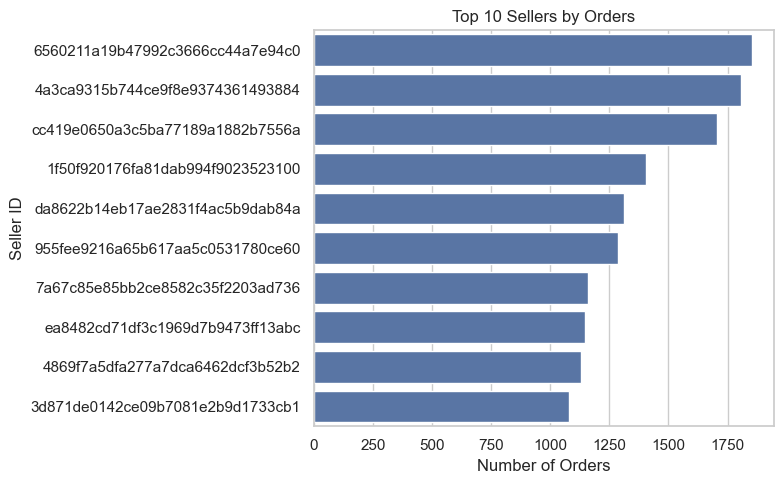

In [16]:
# ======== Top Sellers by Orders ==========

seller_orders = (
    df.groupby("seller_id")["order_id"]
      .nunique()
      .sort_values(ascending=False)
)

top_orders = seller_orders.head(10)
plt.figure(figsize=(8,5))
sns.barplot(x=top_orders.values,y=top_orders.index)
plt.title("Top 10 Sellers by Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Seller ID")
plt.tight_layout()
plt.show()

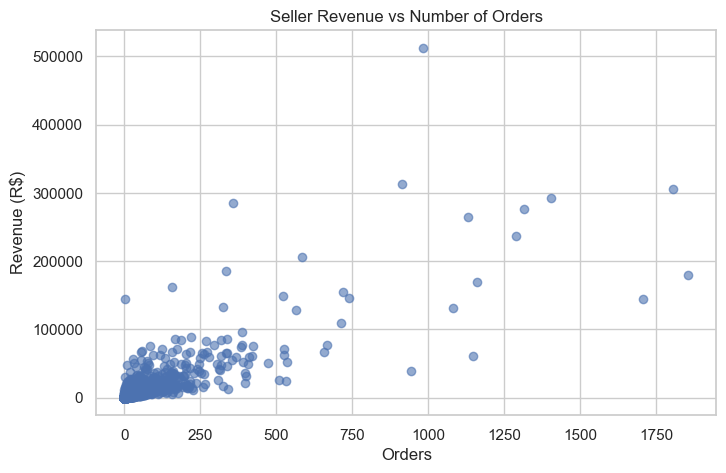

In [17]:
# ======== Average Seller Revenue ==========

seller_summary = (
    df.groupby("seller_id")
      .agg(
          Orders=("order_id", "nunique"),
          Revenue=("payment_value", "sum")
      )
)

# ======== Revenue vs Orders ==========
plt.figure(figsize=(8,5))
plt.scatter(
    seller_summary["Orders"],
    seller_summary["Revenue"],
    alpha=0.6
)
plt.title("Seller Revenue vs Number of Orders")
plt.xlabel("Orders")
plt.ylabel("Revenue (R$)")
plt.show()

# Section 5: Delivery Performance Analysis

In [18]:
# ==========  Delivery Feature Engineering ==============

# Keep only delivered orders
delivery_df = df[df["order_status"] == "delivered"].copy()

# Delivery time (Purchase → Customer Delivery)
delivery_df["delivery_days"] = (
    delivery_df["order_delivered_customer_date"] -
    delivery_df["order_purchase_timestamp"]
).dt.days

# Estimated delivery duration
delivery_df["estimated_delivery_days"] = (
    delivery_df["order_estimated_delivery_date"] -
    delivery_df["order_purchase_timestamp"]
).dt.days

# Delivery difference
delivery_df["delivery_delay_days"] = (
    delivery_df["order_delivered_customer_date"] -
    delivery_df["order_estimated_delivery_date"]
).dt.days

delivery_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,seller_zip_code_prefix,seller_city,seller_state,payment_sequential,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,purchase_date,purchase_month,purchase_year,month_name,delivery_days,estimated_delivery_days,delivery_delay_days
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05,1.0,a9516a079e37a9c9c36b9b78b10169e8,7c67e1448b00f6e969d365cea6b010ab,2017-05-22 15:22:12,124.99,21.88,moveis_escritorio,41.0,1141.0,1.0,8683.0,54.0,64.0,31.0,office_furniture,8577.0,itaquaquecetuba,SP,1.0,credit_card,2.0,146.87,88b8b52d46df026a9d1ad2136a59b30b,4.0,No Title,No Comment,2017-05-26 00:00:00,2017-05-30 22:34:40,14409.0,-20.498489,-47.396929,franca,SP,2017-05-16,2017-05,2017,May,8.0,19,-11.0
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06,1.0,4aa6014eceb682077f9dc4bffebc05b0,b8bc237ba3788b23da09c0f1f3a3288c,2018-01-18 20:58:32,289.00,46.48,utilidades_domesticas,43.0,1002.0,3.0,10150.0,89.0,15.0,40.0,housewares,88303.0,itajai,SC,1.0,credit_card,8.0,335.48,02fc48a9efa3e3d0f1a8ea26507eeec3,5.0,No Title,No Comment,2018-01-30 00:00:00,2018-02-10 22:43:29,9790.0,-23.727992,-46.542848,sao bernardo do campo,SP,2018-01-12,2018-01,2018,January,16.0,24,-8.0
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13,1.0,bd07b66896d6f1494f5b86251848ced7,7c67e1448b00f6e969d365cea6b010ab,2018-06-05 16:19:10,139.94,17.79,moveis_escritorio,55.0,955.0,1.0,8267.0,52.0,52.0,17.0,office_furniture,8577.0,itaquaquecetuba,SP,1.0,credit_card,7.0,157.73,5ad6695d76ee186dc473c42706984d87,5.0,No Title,No Comment,2018-06-15 00:00:00,2018-06-15 12:10:59,1151.0,-23.531642,-46.656289,sao paulo,SP,2018-05-19,2018-05,2018,May,26.0,24,1.0
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10,1.0,a5647c44af977b148e0a3a4751a09e2e,7c67e1448b00f6e969d365cea6b010ab,2018-03-27 16:31:16,149.94,23.36,moveis_escritorio,48.0,1066.0,1.0,12160.0,56.0,51.0,28.0,office_furniture,8577.0,itaquaquecetuba,SP,1.0,credit_card,1.0,173.30,059a801bb31f6aab2266e672cab87bc5,5.0,No Title,No Comment,2018-03-29 00:00:00,2018-04-02 18:36:47,8775.0,-23.499702,-46.185233,mogi das cruzes,SP,2018-03-13,2018-03,2018,March,14.0,27,-13.0
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15,1.0,9391a573abe00141c56e38d84d7d5b3b,4a3ca9315b744ce9f8e9374361493884,2018-07-31 10:10:09,230.00,22.25,casa_conforto,61.0,407.0,1.0,5200.0,45.0,15.0,35.0,home_confort,14940.0,ibitinga,SP,1.0,credit_card,8.0,252.25,8490879d58d6c5d7773f2739a03f089a,5.0,a melhor nota,O baratheon è esxelente Amo adoro

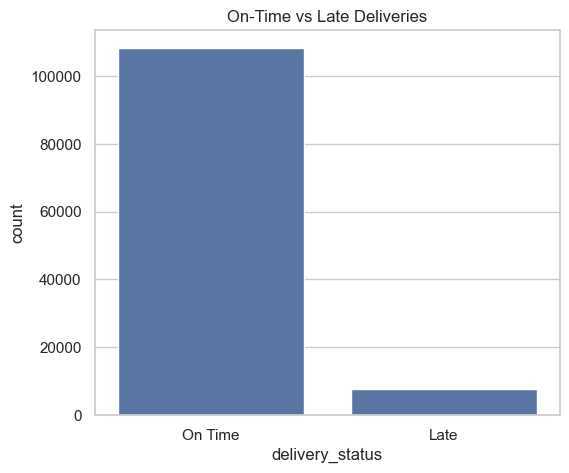

In [19]:
# =========== Delivery Status ============

delivery_df["delivery_status"] = np.where(
    delivery_df["delivery_delay_days"] <= 0,
    "On Time",
    "Late"
)

delivery_status = (delivery_df["delivery_status"].value_counts())
plt.figure(figsize=(6,5))
sns.countplot(data=delivery_df, x="delivery_status")
plt.title("On-Time vs Late Deliveries")
plt.show()

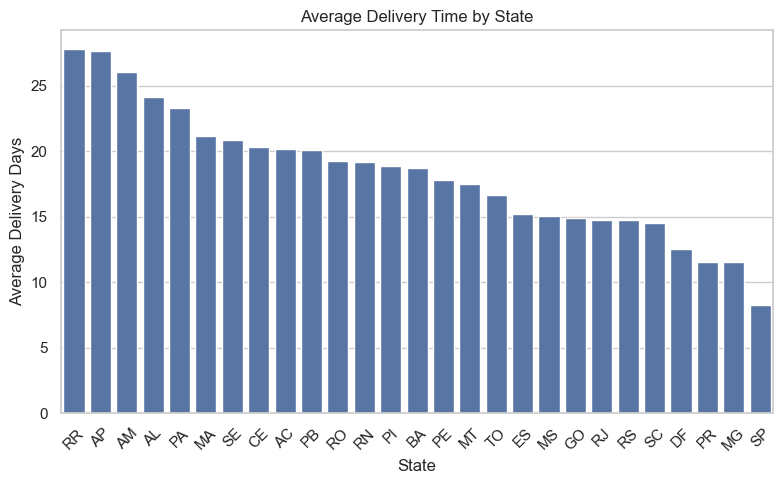

In [20]:
#========= Delivery Time by Customer State ============

state_delivery = (
    delivery_df.groupby("customer_state")["delivery_days"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))
sns.barplot(x=state_delivery.index, y=state_delivery.values)
plt.xticks(rotation=45)
plt.title("Average Delivery Time by State")
plt.xlabel("State")
plt.ylabel("Average Delivery Days")
plt.tight_layout()
plt.show()

In [ ]:
# ========  Logistics KPIs  ===========
    # This creates an executive summary of logistics performance.

logistics_kpis = pd.DataFrame({
    "Metric": [
        "Average Delivery Days",
        "Average Estimated Days",
        "On-Time Delivery %",
        "Late Delivery %",
        "Maximum Delivery Days",
        "Minimum Delivery Days"
    ],
    "Value": [
        round(delivery_df["delivery_days"].mean(), 2),
        round(delivery_df["estimated_delivery_days"].mean(), 2),
        round((delivery_df["delivery_status"] == "On Time").mean() * 100, 2),
        round((delivery_df["delivery_status"] == "Late").mean() * 100, 2),
        delivery_df["delivery_days"].max(),
        delivery_df["delivery_days"].min()
    ]
})

logistics_kpis

,Metric,Value
0,Average Delivery Days,12.02
1,Average Estimated Days,23.47
2,On-Time Delivery %,93.46
3,Late Delivery %,6.54
4,Maximum Delivery Days,209.00
5,Minimum Delivery Days,0.00


# Section 6: Payment Analysis

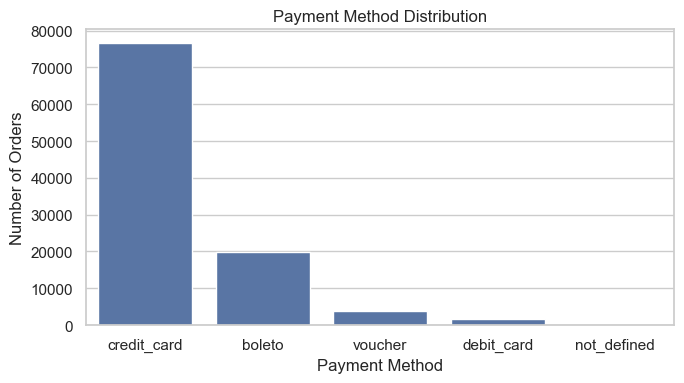

In [25]:
# ===========  Payment Method Distribution =============

payment_method = (
    df.groupby("payment_type")["order_id"]
      .nunique()
      .sort_values(ascending=False)
)

plt.figure(figsize=(7,4))
sns.barplot(x=payment_method.index, y=payment_method.values)
plt.title("Payment Method Distribution")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

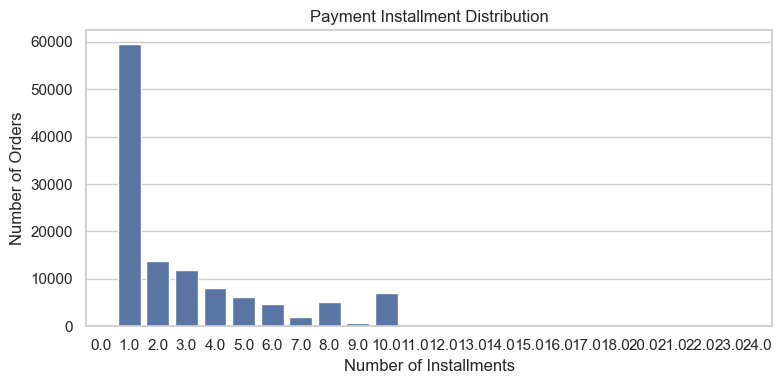

In [28]:
# ========= Installment Distribution =============

installments = (
    df["payment_installments"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8,4))
sns.barplot(x=installments.index,y=installments.values)
plt.title("Payment Installment Distribution")
plt.xlabel("Number of Installments")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

# Section 7: Customer Satisfaction Analysis

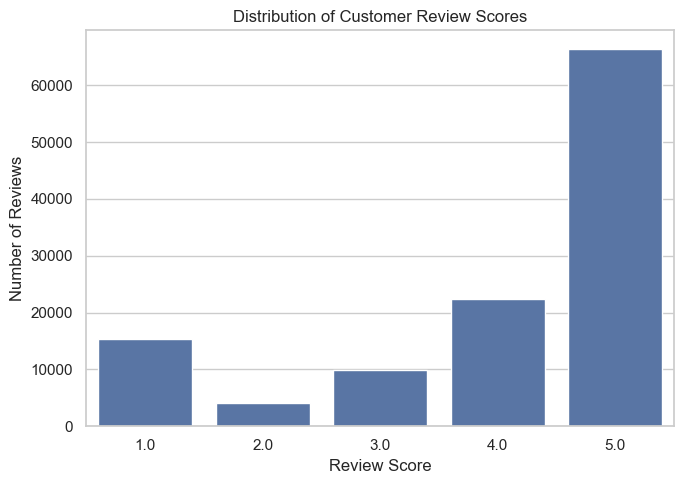

In [31]:
# ===========  Review Score Distribution ===============

review_counts = (
    df["review_score"]
      .value_counts()
      .sort_index()
)

plt.figure(figsize=(7,5))
sns.barplot(x=review_counts.index, y=review_counts.values)
plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

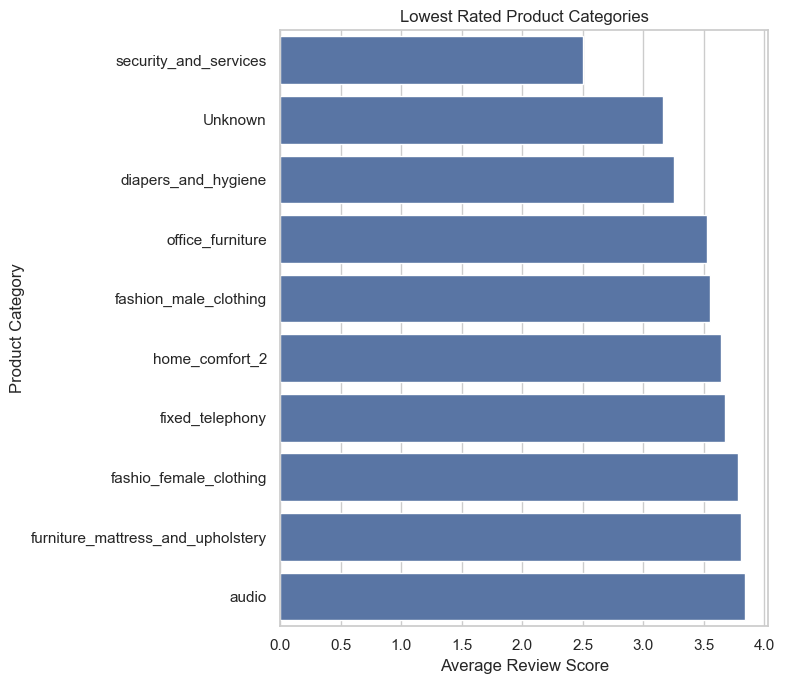

In [ ]:
# =========== Lowest Rated Categories ================

category_rating = (
    df.groupby("product_category_name_english")
      .agg(
          Average_Rating=("review_score", "mean"),
          Orders=("order_id", "nunique")
      )
)

lowest_categories = (category_rating.sort_values("Average_Rating").head(10))
plt.figure(figsize=(8,7))
sns.barplot(x=lowest_categories["Average_Rating"],y=lowest_categories.index)
plt.title("Lowest Rated Product Categories")
plt.xlabel("Average Review Score")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

# Section 8: Geographic Analysis

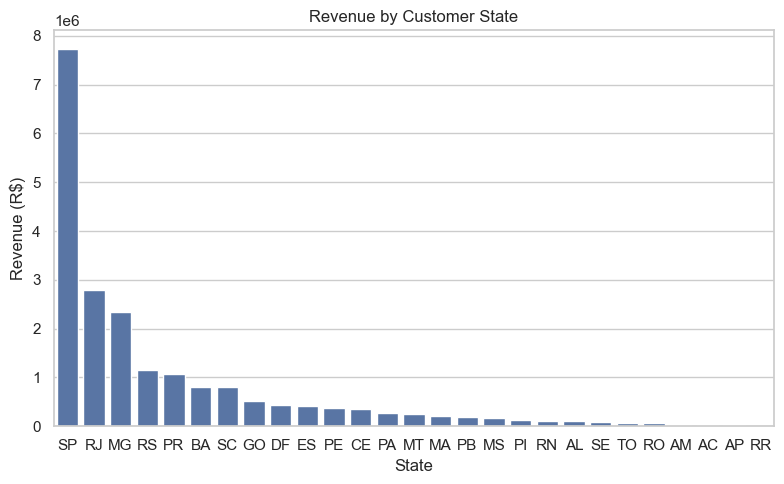

In [41]:
# =========== Revenue by Customer State ============

state_revenue = (
    df.groupby("customer_state")
      .agg(
          Revenue=("payment_value", "sum")
      )
      .sort_values("Revenue", ascending=False)
)

plt.figure(figsize=(8,5))
sns.barplot(data=state_revenue.reset_index(),x="customer_state",y="Revenue")
plt.title("Revenue by Customer State")
plt.xlabel("State")
plt.ylabel("Revenue (R$)")
plt.tight_layout()
plt.show()

In [42]:
# ============  Geographic KPI Dashboard ============

state_reviews = (
    df.groupby("customer_state")
      .agg(
          Average_Review=("review_score", "mean"),
          Orders=("order_id", "nunique")
      )
)
delivery_state = (
    delivery_df.groupby("customer_state")
               .agg(
                   Average_Delivery=("delivery_days", "mean")
               )
               .sort_values("Average_Delivery", ascending=False)
)
state_orders = (
    df.groupby("customer_state")
      .agg(
          Orders=("order_id", "nunique")
      )
      .sort_values("Orders", ascending=False)
)

geo_dashboard = pd.DataFrame({

    "Metric":[
        "Highest Revenue State",
        "Highest Order State",
        "Highest Customer State",
        "Highest Seller State",
        "Fastest Delivery State",
        "Highest Rated State"
    ],

    "Value":[
        state_revenue.index[0],
        state_orders.index[0],
        customer_state.index[0],
        seller_state.index[0],
        delivery_state.sort_values("Average_Delivery").index[0],
        state_reviews.sort_values( "Average_Review",ascending=False).index[0]
    ]
})
geo_dashboard

,Metric,Value
0,Highest Revenue State,SP
1,Highest Order State,SP
2,Highest Customer State,SP
3,Highest Seller State,SP
4,Fastest Delivery State,SP
5,Highest Rated State,AP
